# Exploratory Data Analysis: Open-Ended Survey Responses
## Steps
1. Import the relevant libraries and load the dataset.
2. Inspect the dataset to identify open-ended survey questions.
3. Select the column for analysis and examine missing values, blank responses, and duplicates.
4. Explore the original responses.
5. Preprocess the text.
6. Examine the preprocessed responses.
7. Identify and examine short responses, separating them for further consideration during model development.
8. Prepare the dataset for consistent comparison of the selected topic-modelling approaches.


## 1.IMPORT RELEVANT LIBRARIES

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

#text preprocessing
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from collections import Counter

#visualization
import matplotlib.pyplot as plt

#word counts
from sklearn.feature_extraction.text import CountVectorizer

## 2. IMPORT AND INSPECT DATASET

### 2.1 Import data

In [2]:
def load_data(file_path, sheet_name=0):
    path = Path(file_path)

    # stop early with a clear message if the path is wrong
    if not path.exists():
        raise FileNotFoundError(f"Cannot find {path}. Check the path and file name.")

    # pick the reader from the file ending
    suffix = path.suffix.lower()
    if suffix == ".csv":
        df = pd.read_csv(path)
    elif suffix in {".xlsx", ".xls"}:
        df = pd.read_excel(path, sheet_name=sheet_name)
    else:
        raise ValueError("Supported formats: .csv, .xlsx, .xls")

    print(f"Loaded {len(df):,} rows and {len(df.columns)} columns.")
    return df

raw = load_data("TopicModellingStudentFeedbackData.xlsx")
# Keep a separate working copy of the uploaded dataset.
df = raw.copy()
df.head(2)

Loaded 1,707 rows and 20 columns.


,Subject Code,Gender,US_Status,Race_Ethnicity,FacultySupportResponse,FacultySupport_Approach1_Code,FacultySupport_Approach2_Code,FacutlySupport_MultipleTopics,FacultySupport_Ambiguous,TASupportResponse,TASupport_Approach1_Code,TASupport_Approach2_Code,TASupport_MultipleTopics,TASupport_Ambiguous,PeerSupportResponse,PeerSupport_Approach1_Code,PeerSupport_Approach2_Code,PeerSupport_MultipleTopics,PeerSupport_Ambiguous,COVID_Code
0,1,Male,US Citizen,Non-Hispanic White,"Better handwriting, hard to follow lecture sli...",Teaching Practice,Teaching Practice,No,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PreCOVID
1,2,Male,US Citizen,Asian,Variety of office hours so that all can get he...,Interactions,Interactions,No,No,Variety of office hours so that all can get he...,TA Availability,Interactions,No,No,Communicate,Engagement,Engagement,No,No,PreCOVID


### 2.2 Inspect dataset for open-ended survey questions

In [3]:
#to detect which rows are likely to contain open-ended survey questions, we will check for number of unique values and average number of words in the responses
rows = []
for col in raw.columns:
    s = df[col].dropna().astype(str)
    rows.append({
        "column": col,
        "unique_values": s.nunique(),
        "avg_words": round(s.str.split().str.len().mean(), 1),
    })

col_summary = pd.DataFrame(rows).sort_values("avg_words", ascending=False).reset_index(drop=True)
col_summary

,column,unique_values,avg_words
0,FacultySupportResponse,1671,23.6
1,TASupportResponse,1582,19.9
2,PeerSupportResponse,1345,16.2
3,US_Status,4,1.9
4,FacultySupport_Approach2_Code,3,1.9
5,FacultySupport_Approach1_Code,3,1.8
6,TASupport_Approach1_Code,3,1.7
7,TASupport_Approach2_Code,3,1.6
8,Race_Ethnicity,8,1.5
9,PeerSupport_Ambiguous,2,1.0


In [4]:
#Here, we filter for columns with more than 50 unique values and an average of 4 words per response (this are our open ended questions)
text_cols = [
    col for col in df.columns
    if df[col].dropna().astype(str).nunique() > 50
    and df[col].dropna().astype(str).str.split().str.len().mean() >= 4
]
print(f"The open ended variables are:{text_cols}\n")
print(raw[text_cols].info())

The open ended variables are:['FacultySupportResponse', 'TASupportResponse', 'PeerSupportResponse']

<class 'pandas.DataFrame'>
RangeIndex: 1707 entries, 0 to 1706
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   FacultySupportResponse  1676 non-null   str  
 1   TASupportResponse       1592 non-null   str  
 2   PeerSupportResponse     1375 non-null   str  
dtypes: str(3)
memory usage: 576.1 KB
None


The analysis shows that our data contains 3 open-ended survey questions. The eventual goal is to analyse all three variables and identify the best performing model. This notebook covers the **first step only: the Faculty Support column**. The aim is to build a clear, reproducible pipeline that can later be reused unchanged on the other two columns.

### 2.3 Narrow down to specific text column for analysis

In [5]:
#defining column we want to analyse
chosen_column = "FacultySupportResponse"
# keep only the identifier and the Faculty Support column
faculty_df = df[["Subject Code", "FacultySupportResponse"]].copy() 
faculty_df.head(2)



,Subject Code,FacultySupportResponse
0,1,"Better handwriting, hard to follow lecture sli..."
1,2,Variety of office hours so that all can get he...


In [6]:
# 1. missing values in each column
print("Missing values:")
print(faculty_df.isna().sum())

# 2. blank responses (cells that contain only spaces)
blank = faculty_df["FacultySupportResponse"].dropna().astype(str).str.strip() == ""
print("\nBlank responses:", blank.sum())

# 3. duplicate subject codes
print("Duplicate subject codes:", faculty_df["Subject Code"].duplicated().sum(),"\n")

# overview of types and non-null counts
faculty_df.info()


Missing values:
Subject Code               0
FacultySupportResponse    31
dtype: int64

Blank responses: 0
Duplicate subject codes: 0 

<class 'pandas.DataFrame'>
RangeIndex: 1707 entries, 0 to 1706
Data columns (total 2 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Subject Code            1707 non-null   int64
 1   FacultySupportResponse  1676 non-null   str  
dtypes: int64(1), str(1)
memory usage: 256.5 KB


This check reveals that the FacultySupportResponse has 31 missing values which means that 31 respondents failed to give a response to this specific survey question. The Subject Code has no duplicated record which means that 1707 rows each represents a unique respondent. In the next cell, we drop the rows with missing values

In [7]:
n_before = len(faculty_df)

# drop rows where the Faculty Support response is missing
clean_df = faculty_df.dropna(subset=["FacultySupportResponse"]).copy()

# also drop space-only cells (they are not NA, but they are empty)
clean_df = clean_df[clean_df["FacultySupportResponse"].astype(str).str.strip() != ""]

# reset the row numbers so they run 0, 1, 2, ... again
clean_df = clean_df.reset_index(drop=True)
print(f"Rows before: {n_before}")
print(f"Rows after:  {len(clean_df)}")
print(f"Rows dropped at this point: {n_before - len(clean_df)}")



Rows before: 1707
Rows after:  1676
Rows dropped at this point: 31


### 2.4 Examine text before preprocessing

count    1676.000000
mean       23.639021
std        21.966632
min         1.000000
25%         9.000000
50%        17.000000
75%        31.000000
max       221.000000
Name: word_count_before, dtype: float64

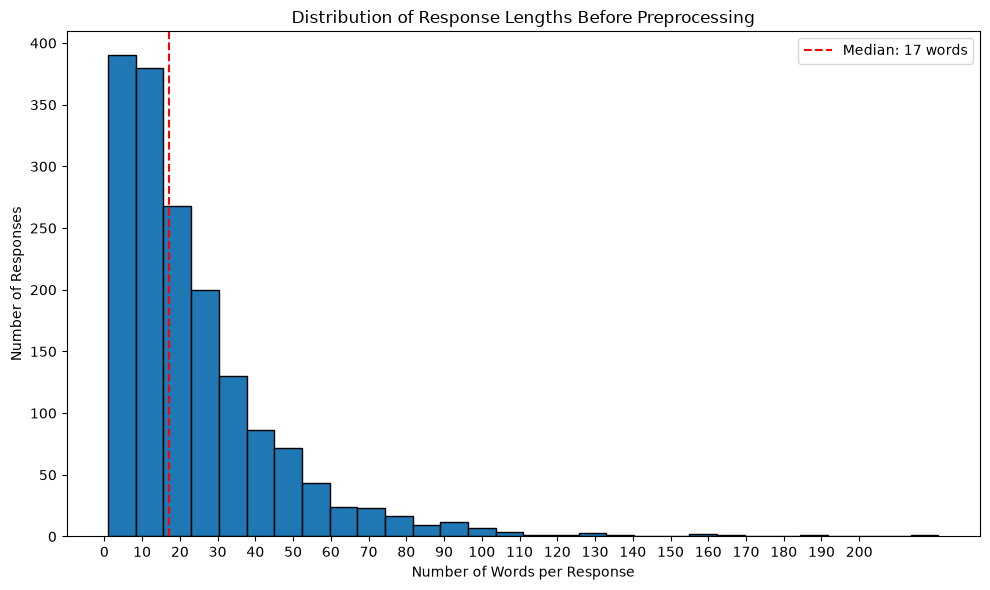

In [8]:
# Examining content in the text column
# Calculate response length before preprocessing
clean_df["word_count_before"]= clean_df["FacultySupportResponse"].str.split().str.len()


# Summary statistics
display(clean_df["word_count_before"].describe())

# Plot response-length distribution
plt.figure(figsize=(10, 6))

plt.hist(
    clean_df["word_count_before"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    clean_df["word_count_before"].median(),
    color="red",
    linestyle="--",
    label=f'Median: {clean_df["word_count_before"].median():.0f} words'
)
plt.xticks(range(0, 201, 10))
plt.title("Distribution of Response Lengths Before Preprocessing")
plt.xlabel("Number of Words per Response")
plt.ylabel("Number of Responses")
plt.legend()
plt.tight_layout()
plt.show()


The Faculty Support dataset contains 1,676 valid responses, with an average length of approximately 24 words and a median of 17 words. Response lengths vary considerably, ranging from 1 to 221 words. The difference between the mean and median suggests a right-skewed distribution, with most responses being relatively short and a smaller number containing substantially more detail.

In [9]:
# lowercase everything and pull out the words (letters only)
text = " ".join(clean_df[chosen_column].astype(str)).lower()
words = re.findall(r"[a-z]+", text)

# count every occurrence, repeats included
word_counts = Counter(words)

print(word_counts.most_common(10))

[('the', 1611), ('to', 1465), ('and', 1126), ('of', 707), ('in', 705), ('a', 658), ('that', 584), ('i', 525), ('for', 522), ('class', 519)]


This check shows the need for removing stopwords. Before our text preprocessing, the most common words are mostly just stop words

## 3. TEXT PREPROCESSING

### 3.1 Define and apply function for text preprocessing

In [10]:
#instantiating stopword and lemmatizer
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

#defining function for preprocessing that can be used for LDA, NMF and KMeans
def clean_text(text):
    text = str(text).lower()                            # 1. lowercase so "Notes" and "notes" count as the same word
    text = re.sub(r"[^a-z\s]", " ", text)               # 2. remove punctuation and numbers
    text = re.sub(r"https?://\S+", " ", text)           # 3. remove weblinks               
    words = word_tokenize(text)                         # 3. tokenize
    words = [w for w in words if w not in stop_words]   # 4. remove stop words
    words = [lemmatizer.lemmatize(w) for w in words]    # 5. lemmatize eg helpful -> help, professors -> professor
    words = [w for w in words if len(w) > 2]            # 6. drop 1 to 2 letter leftovers
    return " ".join(words)


#defining function for preprocessing that will be used for BertTopic (here we are not removing stopwords, lowercasing or removing punctuation)
def clean_for_bertopic(text):
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)   # remove weblinks
    text = re.sub(r"\s+", " ", text).strip()              # collapse extra spaces and line breaks
    return text



In [11]:
#applying text preprocessing to our chosen column and storing the cleaned text in a new column
clean_df["clean_text"] = clean_df["FacultySupportResponse"].apply(clean_text)

clean_df["bert_text"] = clean_df["FacultySupportResponse"].apply(clean_for_bertopic)

clean_df.head(1)

,Subject Code,FacultySupportResponse,word_count_before,clean_text,bert_text
0,1,"Better handwriting, hard to follow lecture sli...",9,better handwriting hard follow lecture slide time,"Better handwriting, hard to follow lecture sli..."


Note that the bert_text largely remains unchanged while their is a clear difference in the new clean_text column (lowercase, no punctuations). In the next steps, we will examine the clean_text column.

### 3.2 Examine preprocessed text

count    1676.000000
mean       12.639618
std        10.807635
min         1.000000
25%         6.000000
50%        10.000000
75%        16.000000
max       108.000000
Name: word_count, dtype: float64

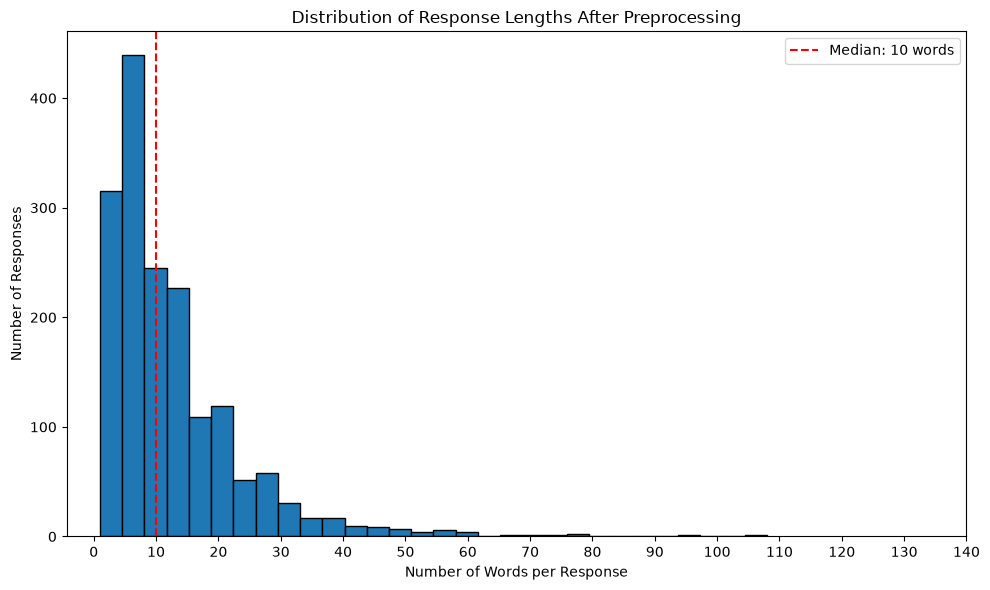

In [12]:

# Calculate response length after preprocessing
clean_df["word_count"] = clean_df["clean_text"].str.split().str.len()

# Summary statistics
display(clean_df["word_count"].describe())

# Plot response-length distribution
plt.figure(figsize=(10, 6))

plt.hist(
    clean_df["word_count"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    clean_df["word_count"].median(),
    color="red",
    linestyle="--",
    label=f'Median: {clean_df["word_count"].median():.0f} words'
)
plt.xticks(range(0, 150, 10))
plt.title("Distribution of Response Lengths After Preprocessing")
plt.xlabel("Number of Words per Response")
plt.ylabel("Number of Responses")
plt.legend()
plt.tight_layout()
plt.show()


Following preprocessing, the average response length decreased from 23.6 to 12.6 words, while the median decreased from 17 to 10 words. This reduction reflects the removal of stopwords and other text elements during cleaning. The relatively short length of the processed responses is an important consideration for topic modelling, particularly for approaches that rely on word frequencies and co-occurrence patterns.

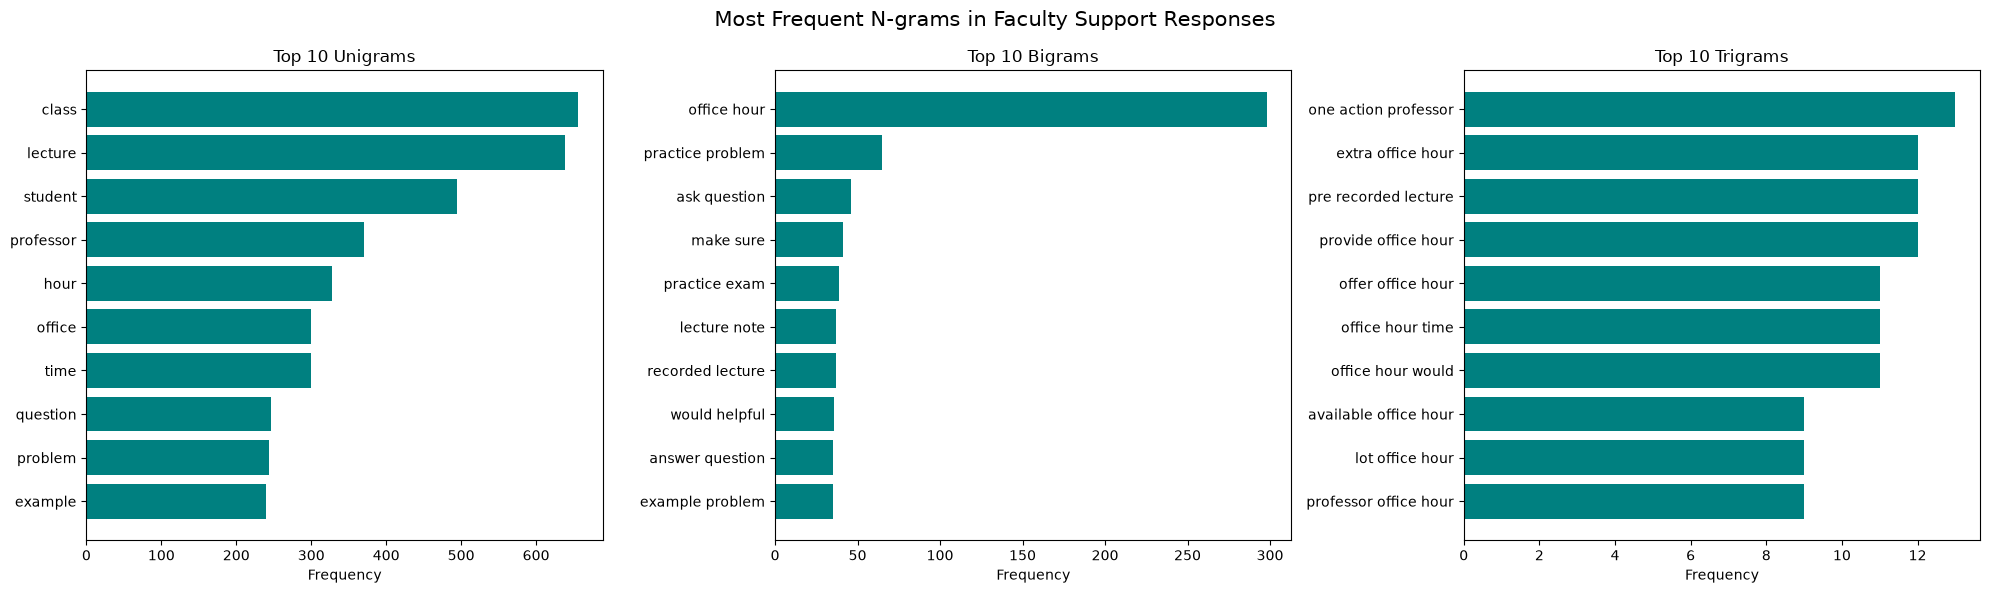

In [13]:

from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, n, title in zip(
    axes,
    [1, 2, 3],
    ["Top 10 Unigrams", "Top 10 Bigrams", "Top 10 Trigrams"]
):
    # Extract n-grams and calculate their frequencies
    vectorizer = CountVectorizer(ngram_range=(n, n))
    matrix = vectorizer.fit_transform(clean_df["clean_text"])

    frequencies = matrix.sum(axis=0).A1

    # Select the 10 most frequent n-grams
    ngram_df = pd.DataFrame({
        "N-gram": vectorizer.get_feature_names_out(),
        "Frequency": frequencies
    }).nlargest(10, "Frequency")

    # Plot
    ax.barh(
        ngram_df["N-gram"],
        ngram_df["Frequency"],
        color="teal"
    )

    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Frequency")

plt.suptitle("Most Frequent N-grams in Faculty Support Responses", fontsize=15)
plt.tight_layout()
plt.show()


The n-gram analysis highlights frequently occurring words and phrases in the cleaned responses. While unigrams identify the most common individual terms, bigrams and trigrams provide additional context by showing words that frequently appear together. These patterns offer an initial indication of recurring concerns in the responses, although further topic modelling is required to identify broader themes.

,Word,Document Frequency,Percentage
0,lecture,490,29.236277
1,class,473,28.221957
2,student,357,21.300716
3,professor,302,18.019093
4,hour,277,16.527446
5,office,261,15.572792
6,time,235,14.021480
7,example,211,12.589499
8,problem,209,12.470167
9,question,208,12.410501


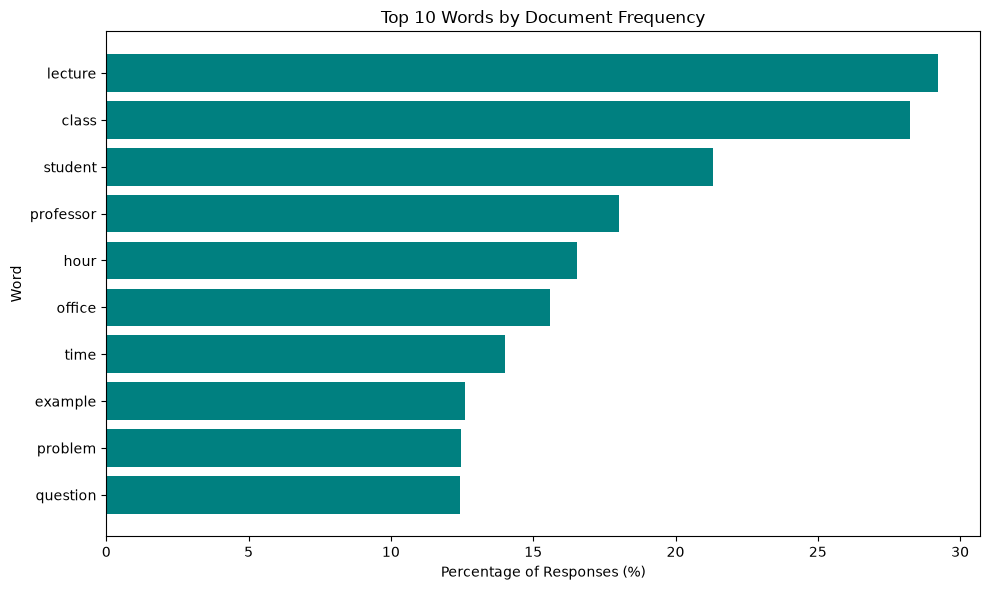

In [14]:

# Calculate document frequency
n_docs = len(clean_df)

doc_freq = Counter(
    word
    for text in clean_df["clean_text"]
    for word in set(text.split())
)

# Top 10 words and their percentages
top_doc_freq = pd.DataFrame(
    doc_freq.most_common(10),
    columns=["Word", "Document Frequency"]
)

top_doc_freq["Percentage"] = (
    top_doc_freq["Document Frequency"] / n_docs * 100
)

display(top_doc_freq)

# Visualize
plt.figure(figsize=(10, 6))

plt.barh(
    top_doc_freq["Word"],
    top_doc_freq["Percentage"],
    color="teal"
)

plt.gca().invert_yaxis()

plt.title("Top 10 Words by Document Frequency")
plt.xlabel("Percentage of Responses (%)")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


Unlike word frequency, which counts the total number of times a word appears across all responses, **document frequency measures how many individual responses contain a particular word**, regardless of how often it appears within each response. This helps identify terms that are widely discussed across respondents rather than those repeated frequently by a smaller number of respondents.

The analysis shows that *lecture* and *class* appear in the largest proportion of responses, at 29.2% and 28.2%, respectively. Other prominent terms include *student*, *professor*, *hour*, and *office*, suggesting that classroom experiences, teaching practices, and instructor availability are common areas of discussion. However, these frequencies do not reveal the specific concerns expressed or the context in which these terms are used, highlighting the need for further topic modelling.

### 3.3 Examine and drop short responses

In [15]:

def examine_short_responses(df, text_col="clean_text", min_words=3):
    df = df.copy()

    # Calculate word count
    df["word_count"] = df[text_col].fillna("").str.split().str.len()

    # Identify short responses
    short_responses = df[df["word_count"] < min_words]

    print(f"Total responses: {len(df)}")
    print(f"Responses with fewer than {min_words} words: {len(short_responses)}")
    print(f"Percentage affected: {len(short_responses) / len(df):.1%}")

    # Display short responses, shortest first
    display(short_responses.sort_values("word_count"))

    return short_responses

short_responses = examine_short_responses(
    clean_df,
    min_words=3
)

Total responses: 1676
Responses with fewer than 3 words: 73
Percentage affected: 4.4%


,Subject Code,FacultySupportResponse,word_count_before,clean_text,bert_text,word_count
640,652,Been flexible,2,flexible,Been flexible,1
572,584,Be flexible,2,flexible,Be flexible,1
1345,1370,Quizzes,1,quiz,Quizzes,1
1553,1581,Discussion,1,discussion,Discussion,1
330,337,more examples,2,example,more examples,1
...,...,...,...,...,...,...
415,423,Clear lectures,2,clear lecture,Clear lectures,2
410,418,Uploading notes,2,uploading note,Uploading notes,2
385,393,Be clear and organized.,4,clear organized,Be clear and organized.,2
490,499,Panopto Recordings,2,panopto recording,Panopto Recordings,2


In [16]:
# Set aside responses with fewer than 3 words for our models
short_df = short_responses.copy()
model_df = clean_df.drop(index=short_df.index).copy()

print(f"Responses retained for modelling: {len(model_df)}")
print(f"Short responses set aside: {len(short_df)}")
model_df.shape

Responses retained for modelling: 1603
Short responses set aside: 73


(1603, 6)

In [17]:
#create the csv which we will use in the modelling step

model_df.to_csv("model_responses.csv", index=False) #excluding the short responses
clean_df.to_csv("all_cleaned_responses.csv", index=False) #including short responses


An examination of response lengths identified 73 responses (4.4%) containing fewer than three words after preprocessing. These responses were set aside because their limited word content may affect the ability of frequency-based topic-modelling approaches to identify meaningful patterns.

To ensure consistency in model evaluation, the remaining 1,603 responses will form the common dataset for comparing the different modelling approaches. LDA, NMF, and TF-IDF + KMeans will use the preprocessed `clean_text`, while BERTopic will use the corresponding `bert_text`, which retains more of the original sentence structure for semantic analysis. Using the same responses across models will allow for a more consistent comparison of their performance.

### EDA Summary

The exploratory analysis extracted a cleaned dataset of 1,676 Faculty Support responses and examined their length, vocabulary and frequently occurring terms. Preprocessing reduced the amount of text while retaining words relevant to the analysis. The findings also highlighted the relatively short nature of many survey responses, which will be considered during model development and evaluation.

The next stage involves applying and comparing different topic-modelling approaches to identify recurring themes in the responses. The preprocessing and analysis procedures developed for the Faculty Support question will subsequently be adapted for the remaining two open-ended survey questions.